# GW250114: Full-sky and Fixed-sky ringdown analysis, step by step

The (2,2,0) + (2,2,1) analysis of GW250114

1. GWOSC strain around the ringdown start, and the arrival times at the fixed IMR sky position.
2. Conditioning (no high-pass, downsampling to 4096 Hz) and 0.2 s analysis windows:
   - **Full-sky:** both detectors start at the arrival time in the last detector;
   - **Fixed-sky:** each detector starts at its own arrival time.
3. Noise covariance from the time-domain autocorrelation of two 64 s off-source stretches.

The strain is read from `strain/` of the Zenodo data if `SKYRING_DATA` is set; otherwise it is downloaded from GWOSC
into `./strain_cache`. `NLIVE` (or `SKYRING_NLIVE`) sets the number of live points; the outputs shown here use $10^4$.

In [1]:
import os
os.environ["JAX_PLATFORM_NAME"] = "cpu"
os.environ["XLA_FLAGS"] = "--xla_force_host_platform_device_count=12"   # CPU devices used by the sampler; before importing jax
os.environ["PATH"] = "/Library/TeX/texbin" + os.pathsep + os.environ["PATH"]   # the plots render text with LaTeX
import sys
sys.path.insert(0, '../src')
import time
import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import numpy as onp
import jax
import jax.numpy as jnp
from jax.scipy.special import logsumexp
import lal
import numpyro
import numpyro.distributions as dist
from numpyro.contrib.nested_sampling import NestedSampler

import waveform as wf
from swsh import swsh
from other_utils import bandpass_ds, analysis_data, td_acf, cholesky_from_acf, decode_termination
from strain_cache import fetch_or_cache_strain
from plot_utils import make_corner_plot, make_amplitude_ratio_plot

jax.config.update("jax_enable_x64", True)
numpyro.enable_x64()
quiet = lambda *a, **k: None

/Users/kallol/miniconda3/envs/skyring/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/kallol/miniconda3/envs/skyring/lib/python3.12/site-packages/jaxns/internals/mixed_precision.py:14: UserWarning: JAX x64 is not enabled. Setting it now. Check for errors.
  warnings.warn("JAX x64 is not enabled. Setting it now. Check for errors.")
INFO:2026-11-25 15:38:26,200:jax._src.xla_bridge:752: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: dlopen(libtpu.so, 0x0001): tried: 'libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OSlibtpu.so' (no such file), '/Users/kallol/miniconda3/envs/skyring/bin/../lib/libtpu.so' (no such file), '/usr/lib/libtpu.so' (no such file, not in dyld cache), 'libtpu.so' (no such file)
INFO:jax._src.xla_bridge:Unable to initialize backend 'tpu': I

In [2]:
## Settings of the paper's GW250114 runs
t_peak, tM = 1420878141.235932, 0.337e-3      # geocentric peak time [GPS] and t_M = G M_f / c^3 (M_f = 68.4 Msun) [s]
t_start = t_peak + 6 * tM                     # geocentric ringdown start
ra, dec = 2.33, 0.19                          # IMR point estimate: sets the arrival times, and the Fixed-sky position
acf_centers = (t_peak - 34, t_peak + 34)      # 64 s off-source stretches, ending 2 s before / starting 2 s after t_peak
modes, modes_220 = ((2, 2, 0), (2, 2, 1)), ((2, 2, 0),)
mass = (55., 95.)
amp = {(2, 2, 0): (0., 4.), (2, 2, 1): (0., 4.)}   # in units of 1e-20
detectors = ("H1", "L1")
seglen, fs, srate, T, t0, trim = 8, 16384, 4096, 0.2, 0.0, 0.25
acf_seglen, taper = 64.0, 0.1
chi = (0., 0.99)
DATA = os.environ.get("SKYRING_DATA")
STRAIN = os.path.join(DATA, "strain") if DATA else "./strain_cache"
NLIVE = int(os.environ.get("SKYRING_NLIVE", 10_000))

In [3]:
## 1. Strain and arrival times at the fixed IMR sky position
raw = {ifo: fetch_or_cache_strain(ifo, t_start - seglen/2, t_start + seglen/2, fs, STRAIN, log=quiet) for ifo in detectors}
det = {"H1": lal.CachedDetectors[lal.LALDetectorIndexLHODIFF], "L1": lal.CachedDetectors[lal.LALDetectorIndexLLODIFF]}
t_lal = lal.LIGOTimeGPS(t_start)
gmst = float(lal.GreenwichMeanSiderealTime(t_lal))
t_arrival = {ifo: t_start + lal.TimeDelayFromEarthCenter(det[ifo].location, ra, dec, t_lal) for ifo in detectors}
ref_det = max(t_arrival, key=t_arrival.get)            # the last detector to see the signal
t_ref = t_arrival[ref_det]
for ifo in detectors:
    print(f"{ifo}: arrival {t_arrival[ifo]:.6f} ({(t_arrival[ifo] - t_ref) * 1e3:+.3f} ms from {ref_det})")

H1: arrival 1420878141.221026 (+0.000 ms from H1)
L1: arrival 1420878141.218555 (-2.470 ms from H1)


In [4]:
## 2. Conditioning and analysis windows (n samples of 0.2 s at 4096 Hz)
n = wf.Ntime(srate, T)
def window(ifo, t_begin):
    """Condition the strain so that a sample falls on t_begin, then take n samples from the one closest to it."""
    times, data = bandpass_ds(raw[ifo], t0=t_begin, ds=fs // srate, trim=trim, f_min=None)   # no high-pass
    return jnp.asarray(analysis_data(data, times, t_begin, n)[1], dtype=jnp.float64)

h_full = {ifo: window(ifo, t_ref) for ifo in detectors}               # Full-sky: common start at t_ref
h_fixed = {ifo: window(ifo, t_arrival[ifo]) for ifo in detectors}     # Fixed-sky: each detector's own arrival
first = min(t_arrival, key=t_arrival.get)
print(f"{n} samples per detector; Full-sky drops the first {(t_ref - t_arrival[first]) * 1e3:.2f} ms of the {first} ringdown")

820 samples per detector; Full-sky drops the first 2.47 ms of the L1 ringdown


In [5]:
## 3. Noise covariance: average time-domain autocorrelation of the off-source stretches, then its Cholesky factor
acf = {ifo: [] for ifo in detectors}
for c in acf_centers:
    for ifo in detectors:
        stretch = fetch_or_cache_strain(ifo, c - acf_seglen/2, c + acf_seglen/2, fs, STRAIN, log=quiet)
        times, data = bandpass_ds(stretch, t0=c, ds=fs // srate, trim=trim, f_min=None)   # conditioned like the data
        acf[ifo].append(td_acf(data, n, taper=taper))
L = {ifo: cholesky_from_acf(onp.mean(acf[ifo], axis=0)) for ifo in detectors}           # C = L L^T

## detector responses and locations used by the likelihoods
wf.set_detectors(*(jnp.asarray(det[ifo].response, dtype=jnp.float64) for ifo in detectors))
wf.set_detector_locations(*wf.initialize_det_locs())

In [6]:
## 4. Log-likelihoods (without the parameter-independent normalization) and priors
def swsh_fn(l, m, iota):
    return swsh(2, l, m, iota, 0.0)

def make_loglik(md, sky):
    table = wf.load_qnm_table("../data", md)
    if sky == "full":       # theta = [M, chi, (A, phi) per mode, cos iota, ra, sin dec, psi]
        return lambda th: wf.ln_likelihood_general_full_jit(h_full["H1"], h_full["L1"], th, gmst, L["H1"], L["L1"],
                                                             table, md, swsh_fn, T, srate, t0, ref_det)
    # Fixed-sky: theta = [M, chi, (A, phi) per mode, cos iota, psi], sky fixed at (ra, dec)
    return lambda th: wf.ln_likelihood_general_fixed_sky_prealigned_jit(h_fixed["H1"], h_fixed["L1"], th, gmst,
                                                                         L["H1"], L["L1"], table, md, swsh_fn,
                                                                         ra, dec, T, srate, t0)

def prior_box(md, sky):
    low, high = [mass[0], chi[0]], [mass[1], chi[1]]
    for mode in md:
        low += [amp[mode][0], 0.]; high += [amp[mode][1], 2*onp.pi]           # amplitude, phase
    low.append(-1.); high.append(1.)                                          # cos iota
    if sky == "full":
        low += [0., -1.]; high += [2*onp.pi, 1.]                              # ra, sin dec
    low.append(0.); high.append(onp.pi)                                       # psi
    return jnp.array(low), jnp.array(high)

In [7]:
## Nested sampling (jaxns through numpyro): stops when ln(Z_dead + Z_live) - ln(Z_dead) < 0.01
def nested_sampling(loglik, low, high, nlive=NLIVE, seed=31567, max_samples=None, label=""):
    def model():
        theta = numpyro.sample("theta", dist.Uniform(low, high))
        numpyro.factor("loglike", loglik(theta))
    rng_run, rng_post = jax.random.split(jax.random.PRNGKey(seed))
    ns = NestedSampler(model, constructor_kwargs=dict(num_live_points=nlive, verbose=False,
                                                      max_samples=max_samples or max(500_000, 10 * nlive * len(low))),
                       termination_kwargs=dict(dlogZ=0.01))
    start = time.time()
    ns.run(rng_run)
    r = ns._results
    reasons, converged = decode_termination(int(r.termination_reason))
    theta = onp.asarray(ns.get_samples(rng_post, num_samples=100_000)["theta"])
    print(f"  {label:22s} ln Z = {float(r.log_Z_mean):.2f} +- {float(r.log_Z_uncert):.2f} "
          f"({'converged' if converged else 'NOT converged: ' + ', '.join(reasons)}; {(time.time() - start) / 60:.1f} min)")
    return theta, float(r.log_Z_mean), float(r.log_Z_uncert)

In [8]:
## 5. Both models, both sky treatments, and ln B
results = {}
for sky in ("full", "fixed"):
    out = {}
    for md in (modes, modes_220):
        low, high = prior_box(md, sky)
        out[md] = nested_sampling(make_loglik(md, sky), low, high, label=f"{sky}-sky {'+'.join(''.join(map(str, m)) for m in md)}")
    theta, lnZ, err = out[modes]; _, lnZ_220, err_220 = out[modes_220]
    ratio = theta[:, 4] / theta[:, 2]                                         # A221 / A220
    results[sky] = dict(theta=theta, lnB=lnZ - lnZ_220)
    print(f"{sky}-sky: ln B = {lnZ - lnZ_220:.2f} +- {onp.hypot(err, err_220):.2f}; A221/A220 median {onp.median(ratio):.3f} "
          f"[{onp.percentile(ratio, 5):.3f}, {onp.percentile(ratio, 95):.3f}]")

INFO:jaxns:Number of Markov-chains set to: 10000


Running over 12 devices.
  full-sky 220+221       ln Z = -821.17 +- 0.05 (converged; 41.3 min)


INFO:jaxns:Number of Markov-chains set to: 10000


Running over 12 devices.


INFO:jaxns:Number of Markov-chains set to: 10000


  full-sky 220           ln Z = -828.58 +- 0.05 (converged; 26.3 min)
full-sky: ln B = 7.41 +- 0.07; A221/A220 median 1.325 [0.833, 1.738]
Running over 12 devices.
  fixed-sky 220+221      ln Z = -820.99 +- 0.05 (converged; 29.3 min)


INFO:jaxns:Number of Markov-chains set to: 10000


Running over 12 devices.
  fixed-sky 220          ln Z = -830.28 +- 0.04 (converged; 19.3 min)
fixed-sky: ln B = 9.29 +- 0.07; A221/A220 median 1.269 [0.887, 1.583]


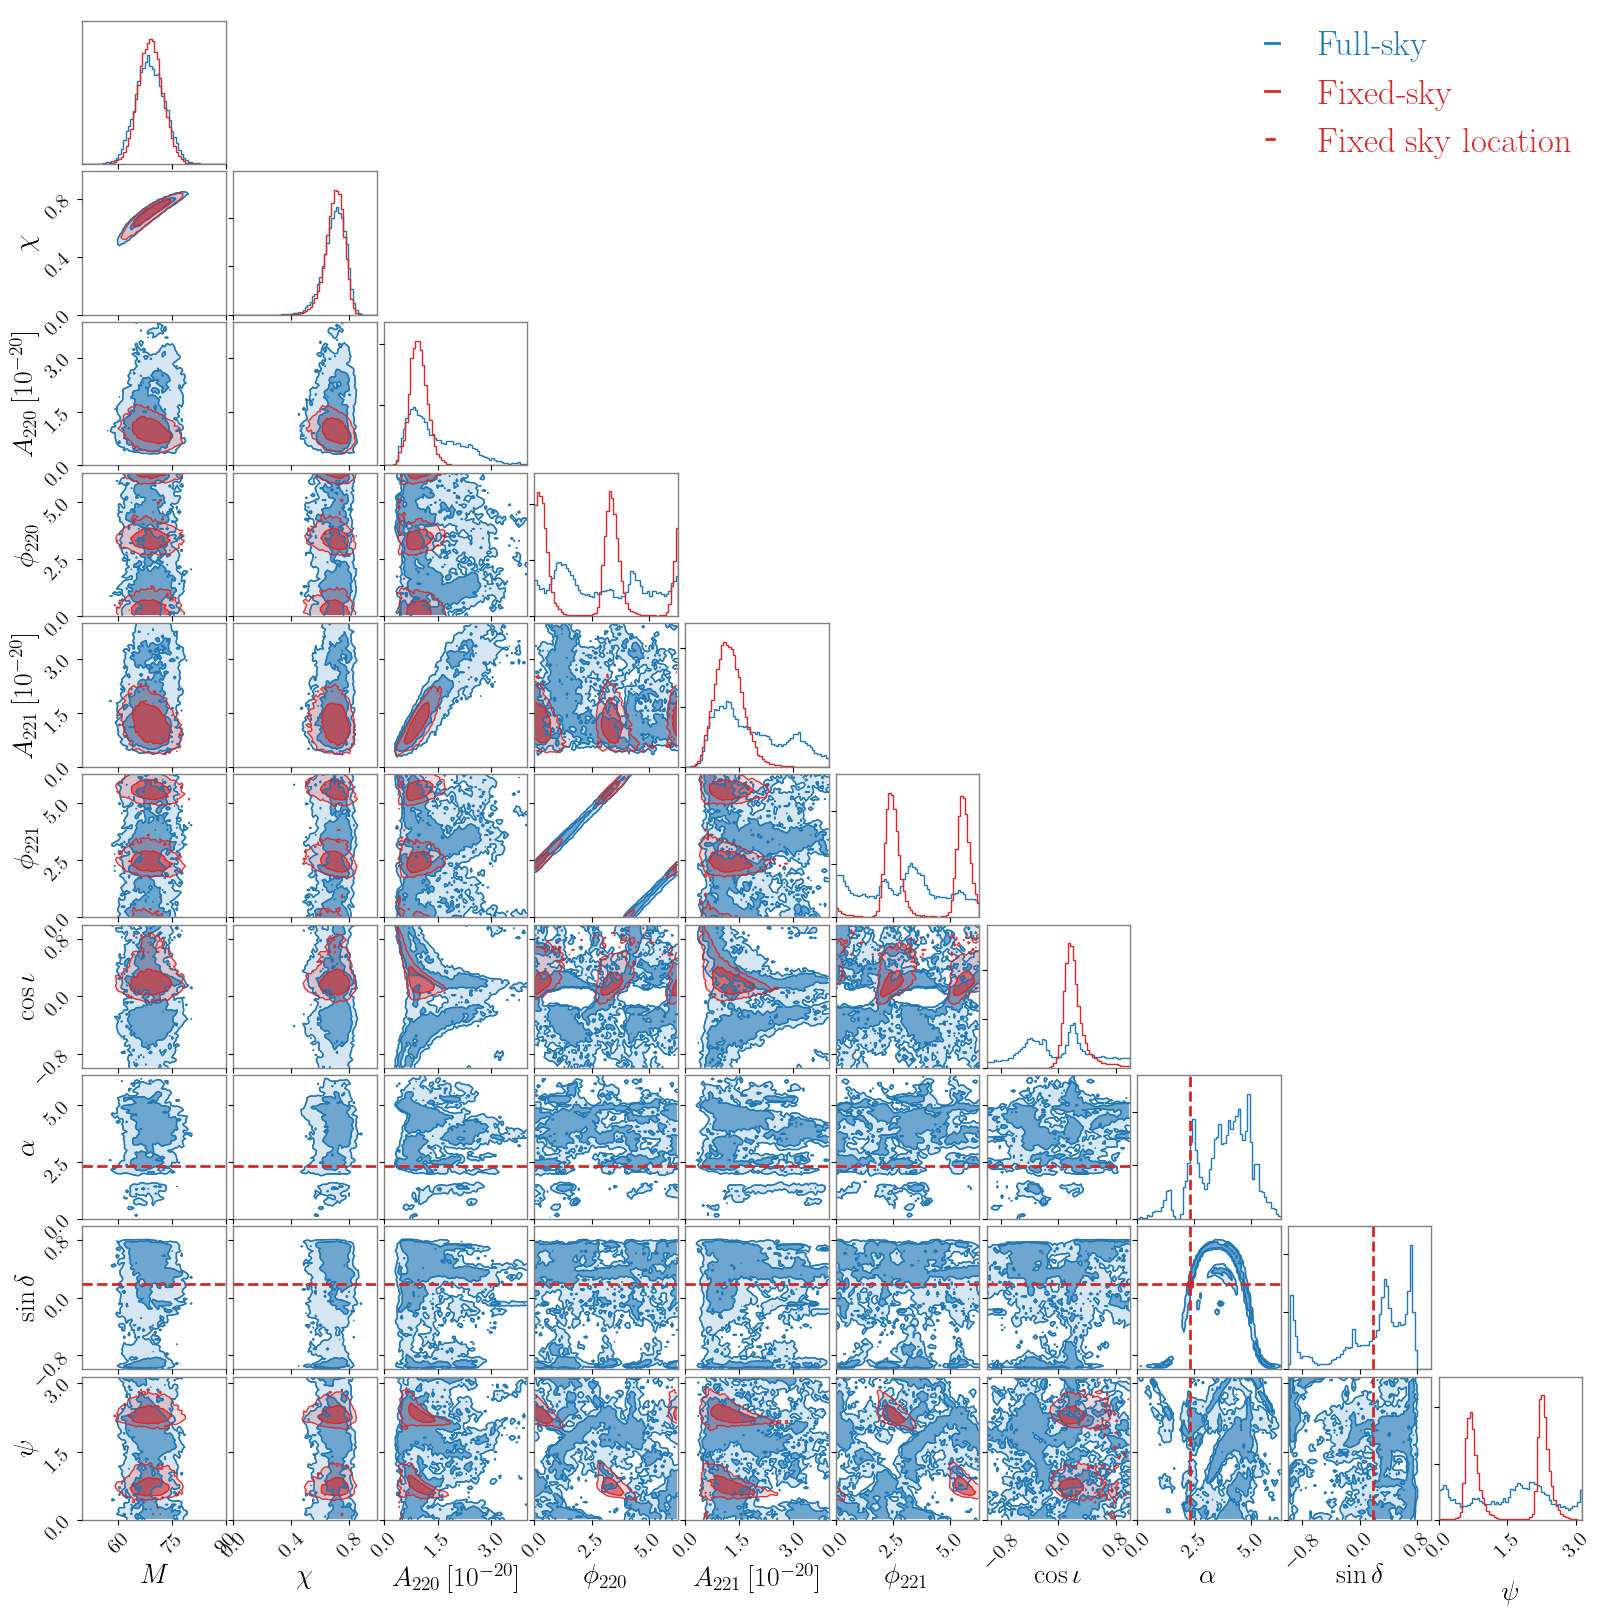

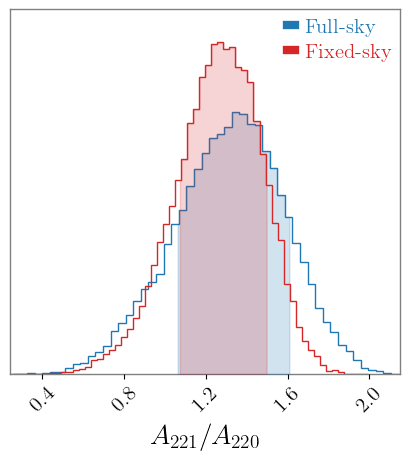

In [9]:
## 6. Posteriors: Full-sky vs Fixed-sky (68% and 95% regions), and the amplitude ratio
names = ["M", "chi", "A220", "phi220", "A221", "phi221", "cosiota", "ra", "sindec", "psi"]
def latex(name):
    if name.startswith("A"):
        return rf"$A_{{{name[1:]}}}\,[10^{{-20}}]$"
    if name.startswith("phi"):
        return rf"$\phi_{{{name[3:]}}}$"
    return {"M": r"$M$", "chi": r"$\chi$", "cosiota": r"$\cos\iota$", "ra": r"$\alpha$", "sindec": r"$\sin \delta$",
            "psi": r"$\psi$"}[name]
labels = [latex(x) for x in names]
datasets = [{"samples": results["full"]["theta"], "params": labels, "label": "Full-sky", "color": "#1f77b4"},
            {"samples": results["fixed"]["theta"], "params": [p for p in labels if p not in (latex("ra"), latex("sindec"))],
             "label": "Fixed-sky", "color": "#d62728"}]
make_corner_plot(datasets=datasets, full_sky_params=labels, bounds=None,
                 fixed_sky_location={"alpha": ra, "sin_delta": onp.sin(dec), "color": "#d62728", "label": "Fixed sky location"})
make_amplitude_ratio_plot(datasets=datasets, numerator_index=4, denominator_index=2, ratio_label=r"$A_{221}/A_{220}$", bins=60)